# ccdl: a controller and its adapter

This is a demo of the basic usage of the **(cerebello-cortical) distributed learning** model (aka **ccdl**).

## The idea

The key idea is to split learning between a ***transient*** component (the *adapter*, or *cerebellum*) and a more ***stable*** one (the *controller*, or *cortex*). The system can then adjust rapidly to new conditions, while preserving the long-term changes to conditions that last long enough.

The schematic below interprets distributed learning as a sweet spot between making memories fully plastic/adaptive (plastic controller, left) and fully preserved/stable (plastic adapter, right).

<center><img src="assets/DL.png" width="800"></center>

## The task

This demo is a simplified version of the procedures used in the paper. It shows how we build the system, train it on adaptation tasks, and test it on a center-out reaching task.

Here, the model only needs to translate a pre-defined motor plan into the corresponding motor command (the signal to send to the body to obtain the planned behavior). Adaptation is then a modification of the *target output*, while the planned trajectory (the network input) stays unchanged. This may sound a little unintuitive at first, but there is a simple reason for this setup: we only want to study the mapping from motor plan to motor command, and how it changes with learning, not the full motor process.

For motor control people: we are looking at the inverse-model part of the motor system, and at how it adapts. The plant is the instantaneous mapping from the two joint angles to the hand position (no torques, no masses, no forces). Again, the objective is not to get a realistic representation, but to study the mechanisms through which representations can be adapted in a robust way.

## The model

The model splits the circuit into two modules:

- a **controller**, a recurrent network that generates the baseline motor command for the two-joint arm;
- an **adapter**, a feed-forward network that watches what the controller is doing and adds a **correction** to its command. The correction is also **fed back** into the controller as an error signal.

## This notebook

We build the model up in three steps, following the paper:

| | What you will do |
|---|---|
| **Part 1 — Controller alone** | See how error feedback corrects a rotation, look at the controller's neural activity, and compare a plastic and a fixed controller through perturbation and washout | 
| **Part 2 — Controller + adapter** | Train the compound model on a rotation with two learning rules (backprop and local), then switch parts of the model off with `model_state` to see what the adapter has learned |
| **Part 3 — Savings** | Adapt, un-adapt, adapt again, and compare the first and the second adaptation |

## Parameters to play with

Every cell with parameters you can change starts with a `🎛 PARAMETERS` banner. Change the values and re-run the cell (and the ones after it that use them).

| Where | Parameter | What it does |
|---|---|---|
| Setup | `SEED` | random seed |
| Part 1 — rotation | `ANGLE_DEMO` | rotation shown in the task and output-trajectory plots (degrees) |
| Part 1 — output trajectories | `GAIN_WEAK`, `GAIN_STRONG` | the two effective feedback gains compared |
| Part 1 — systematic error | `angles`, `gains` | rotation sweep and effective feedback gains |
| Part 1 — neural activity | `PERT_ANGLE`, `GAINS` | rotation, and the raw `model.gain` values used for the latent space |
| Part 1 — washout | `WASHOUT_PHASES`, `FIXED_GAIN` | perturbation / washout schedule, feedback gain of the fixed controller |
| Part 2 — training | `ANGLE`, `EPOCHS`, `LR_CB`, `LR_CX`, `LOCAL_LR`, `FB_GAIN` | rotation, training length, learning rates, adapter → controller feedback gain |
| Part 2 — training | `STATE_BP`, `STATE_LOCAL` | which weights learn (`modules_plasticity`) and with which rule |
| Part 2 — ablations | `ABLATION_GAIN` | feedback gain used in the second ablation plot |
| Part 3 — savings | `PHASES`, `SAVINGS_STATE` | rotation schedule, and the learning rule used |

The plotting code is in `demo_plots.py`, next to this notebook: you can skip reading it.

## Terminology: paper vs. code

The paper says *controller* and *adapter*. The code was written first, with *cortex* and *cerebellum*, and keeps those names.

| Paper | Code | What it is |
|---|---|---|
| **Controller** | `model.cortex` — keys `cortex_*`, learning rate `cx_lr`, prefix `cx` | Recurrent network (RNN). Produces the motor command (joint angles). |
| **Adapter** | `model.cerebellum` — keys `cereb_*`, learning rate `cb_lr`, prefix `cb` | Feed-forward network. Adds a correction to the controller's command and feeds a signal back to it. |
| Plant | `model.plant` (`TwoJointsArm`) | Maps joint angles to hand position (x, y). |
| Controller memory ("no adapter") | `nocb`, `CX_ONLY` | The output of the same network with the adapter switched off. |
| Compound model | `CerebelloCorticalNet` | Controller + adapter + plant. |
| Model state | `model_state` | Dictionary used to control the model configuration (see Part 2)| 

In [ ]:
import os, json, time
from copy import deepcopy
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt

from ccdl.paths import PRETRAINED_DIR
from ccdl.utils import load_var, fb_nuc_norm
from ccdl.ccnet import CerebelloCorticalNet
from ccdl.pre_trainer import CCNetPreTrainer
from ccdl.reaching import ReachingDataset
from demo_utils import (plot_task, plot_controller_outputs, plot_systematic_error, plot_latent_3d,
                        plot_washout, plot_adaptation_loss, plot_adaptation_reaches, plot_ablations,
                        plot_savings)   # plotting helpers, see demo_utils.py

PRE  = PRETRAINED_DIR
# ══════ 🎛  PARAMETERS: change and re-run ══════
SEED = 24
# ═══════════════════════════════════════════════
np.random.seed(SEED); torch.manual_seed(SEED)
mse = nn.MSELoss()

In [2]:
CX_PRE = PRE / "cortex"
cfg = json.load(open(CX_PRE / "train_cfg.json"))

def load_controller():
    """
    Load controller and dataset genrator
    """
    reaching = ReachingDataset({**cfg["dataset_params"], "device": torch.device("cpu")})
    net_params = {**cfg["net_params"], "device": torch.device("cpu"), "dtype": torch.float32}
    model = CerebelloCorticalNet(reaching.input_size[2], cfg["rnn_hidden_size"], **net_params)
    model.cortex.load_state_dict(load_var(CX_PRE / "model.sd"))
    model.eval(**cfg["model_state"])
    return model, reaching

def rotate(reaching, angle):
    "Apply a rotation of `angle` degrees; return cartesian targets and joint-angle targets."
    reaching.apply_perturbation(dict(angle=angle, amplitude_factor=1.0, translation=[0.0, 0.0]))
    inputs, targets = reaching.generate_perturbed_dataset("cart")
    _, angle_targets = reaching.generate_perturbed_dataset("angles")
    return inputs, targets, angle_targets

def run_controller(effective_gain, angle):
    inputs, targets, angle_targets = rotate(reaching, angle)               # apply rotation
    ctrl.gain = effective_gain / fb_nuc_norm(ctrl)                         # modify the feedback gain
    with torch.no_grad():
        out = ctrl(inputs, input_2=angle_targets, input_2_type="angles")   # error feedback
    return out, targets

ctrl, reaching = load_controller()
print("Model state structure:")
print("controller-only model_state",json.dumps(cfg["model_state"],indent=4))

Model state structure:
controller-only model_state {
    "cereb_feedback": false,
    "cereb_readout": false,
    "modules_plasticity": {
        "cortex_hw": true,
        "cortex_hb": true,
        "cortex_in": true,
        "cortex_out": false,
        "cereb_to_cortex": false,
        "cereb": false
    },
    "local_plasticity": false,
    "plant": true
}


# Part 1 — The controller alone

We start from the pretrained **controller**, a recurrent network driving a two-joint arm. It was trained on the baseline task only, with no change to the output. Thanks to its output feedback, it is nevertheless able to generalize to rotations of the target **without any further training**.

In the paper, we show that the feedback weights can be trained, but also that they can simply be **fixed to the pseudoinverse** of the output weights. The error signal then pushes the command in the direction that reduces the error.

<center><img src="assets/pseudo.png" width="500"></center>

Here, we test this generalization by applying rotations to the target output trajectories. The amount of correction is controlled by `model.gain`, which scales the feedback signal. In the plots, we report the **effective feedback gain** $\kappa\,\|W_{fb}\|_*$, where $\kappa$ is `model.gain`.

### The task: a visuomotor rotation

Each reach starts from the same point and moves to its own target. A rotation turns every target around the starting point (arrows). The controller then has to produce hand paths that follow the **rotated** targets (red) instead of the original ones (grey), while receiving the same input as before.

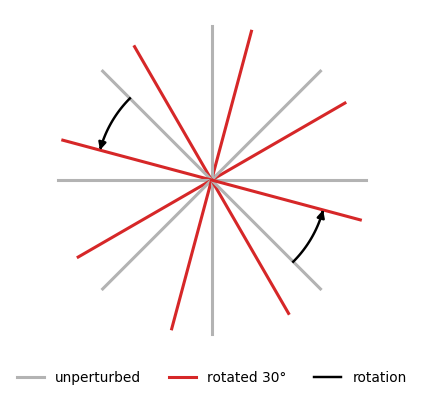

In [4]:
# ══════ 🎛  PARAMETERS: change and re-run ══════
ANGLE_DEMO = 30          # rotation (degrees, integer)
# ═══════════════════════════════════════════════

_, targets_ref = reaching.generate_unperturbed_dataset("cart")
_, targets_rot, _ = rotate(reaching, ANGLE_DEMO)
plot_task(targets_ref, targets_rot, ANGLE_DEMO); plt.show()

### Output trajectories under a rotation (paper S3b)

How much does the feedback correct? Here, we run the same controller on the rotated task with **weak** (`GAIN_WEAK`, effective gain 1) and **strong** (`GAIN_STRONG`, effective gain 50) error feedback.

With weak feedback, the hand paths stay close to the original, unrotated reaches. With strong feedback, they are pulled onto the rotated targets. Each colour is a reach direction, crosses mark the final target positions, and dashed lines (right) the target trajectories. Dots along the paths are evenly spaced in time, so wider spacing means faster movement.

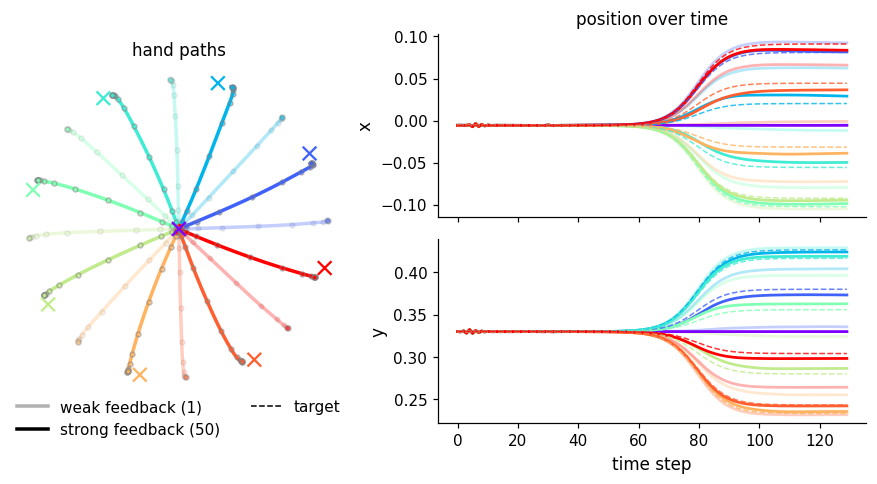

In [5]:
colors = plt.get_cmap("rainbow")(np.linspace(0, 1, reaching.input_size[1]))

# ══════ 🎛  PARAMETERS: change and re-run ══════
GAIN_WEAK, GAIN_STRONG = 1, 50       # effective feedback gains to compare
# ═══════════════════════════════════════════════

runs = []
for gain, alpha, label in [(GAIN_WEAK, 0.3, f"weak feedback ({GAIN_WEAK})"),
                           (GAIN_STRONG, 1.0, f"strong feedback ({GAIN_STRONG})")]:
    out, targets = run_controller(gain, ANGLE_DEMO)
    runs.append((label, out, alpha))
plot_controller_outputs(runs, targets, colors); plt.show()

### Systematic error vs. rotation angle (paper S3d)

How large a rotation can the feedback compensate? Here, we sweep rotations from −90° to +90° and measure the error that remains once the feedback has acted, for three effective gains. Each point represents the MSE on the entire trajectory, normalised by the standard deviation of the unperturbed targets, for a specific rotation and gain value.

Without feedback (gain 0), the error grows with the size of the rotation. Higher gains leave a smaller residual error at every angle.

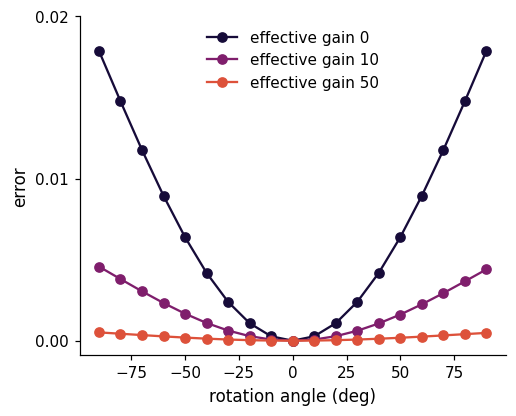

In [6]:
# ══════ 🎛  PARAMETERS: change and re-run ══════
angles = np.arange(-90, 91, 10)      # rotations to sweep (degrees)
gains  = [0, 10, 50]                 # effective feedback gains
# ═══════════════════════════════════════════════
std = reaching.generate_unperturbed_dataset("cart")[1].std().item()

errors = {}
for g in gains:
    errors[g] = [mse(*run_controller(g, a)).item() / std for a in angles]
plot_systematic_error(angles, errors); plt.show()

### Neural activity of the controller (paper Fig. 2e)

What does the feedback do to the controller's recurrent activity? Here, we look at it in a 3-D latent space, **without** a rotation (top) and **with** a `PERT_ANGLE` = 40° rotation corrected by strong feedback (bottom, `model.gain` = 30). Both panels use the same axes:

- **Latents 1 and 2** are the two readout dimensions (the rows of the output weights), so they follow the commanded joint angles.
- **Latent 3** is the first principal axis of the activity, i.e. the dominant mode of neural activity. It is computed on the activity pooled over the feedback gains in `GAINS` (0 and 30) on the rotated task, after min–max normalising each neuron over time and tasks.
- Trajectories are shown from movement onset on.

Solid lines are the controller's trajectories, and faint lines their projection on the floor. Dashed lines are the joint-angle targets. In the bottom panel, the **initial targets** are kept as light dashed lines, the **new (rotated) targets** are dash-dotted, and the arrow points from the old to the new end point of one reach. Each colour is a reach direction.

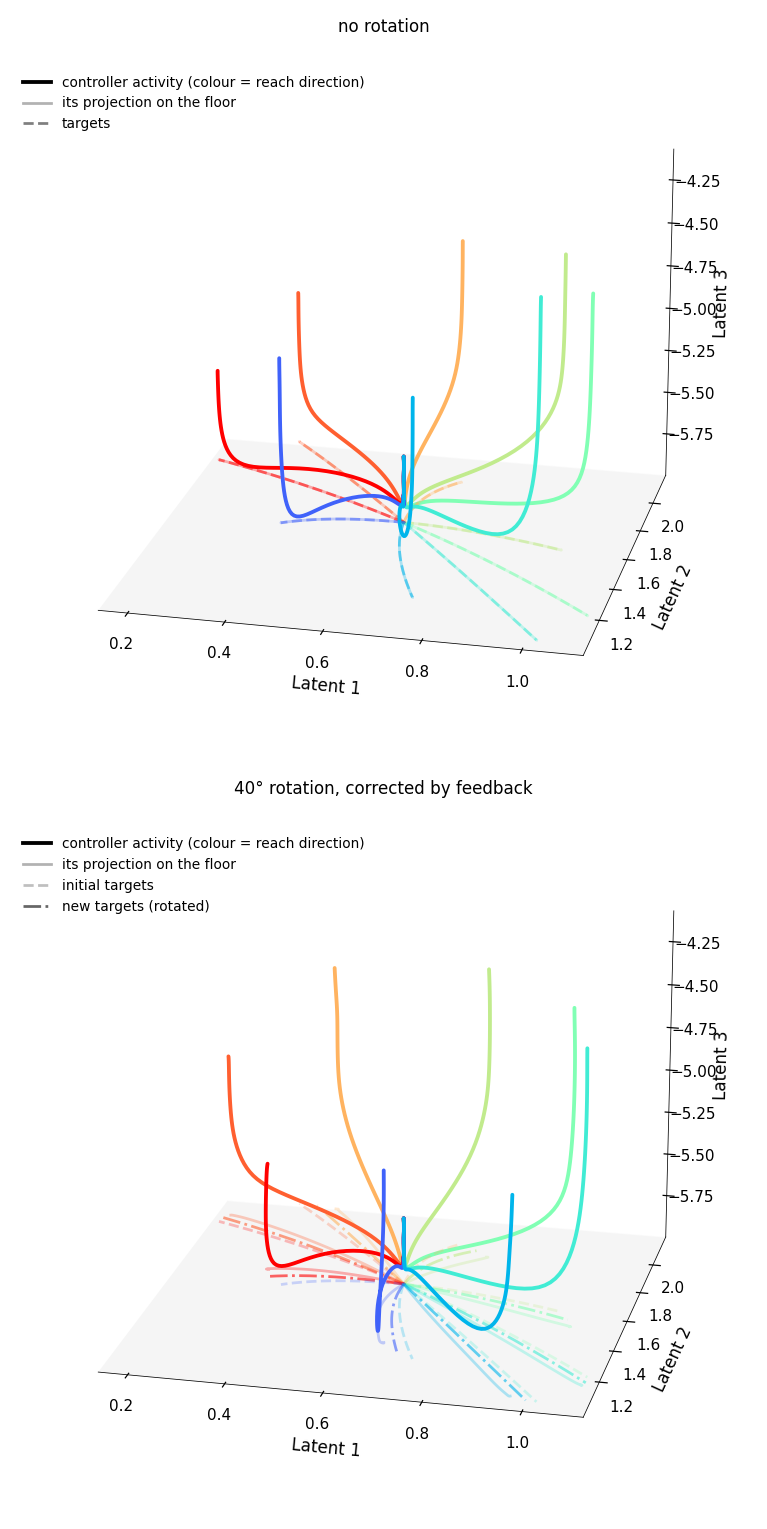

In [7]:
# ══════ 🎛  PARAMETERS: change and re-run ══════
PERT_ANGLE = 40                                             # rotation (degrees)
GAINS      = {"no feedback": 0, "strong feedback": 30}   # raw model.gain (keep the "strong feedback" key)
# ═══════════════════════════════════════════════
ORDER      = [5, 4, 6, 3, 7, 0, 8, 1, 2]                                # order in which tasks are drawn
START      = 30                                                         # movement onset (end of hold period)

inputs, _, t_angles = rotate(reaching, PERT_ANGLE)
acts = {}
for name, g in GAINS.items():
    ctrl.gain = g
    with torch.no_grad():
        _, hidden = ctrl(inputs, input_2=t_angles, input_2_type="angles", return_hidden=True)
    acts[name] = hidden                                          # (time, tasks, hidden)

def minmax(a):                                                   # per neuron, over time and tasks
    lo, hi = a.amin(dim=(0, 1)), a.amax(dim=(0, 1))
    return (a - lo) / (hi - lo)

pooled = torch.cat([minmax(a) for a in acts.values()], dim=0).numpy()     # (3*time, tasks, hidden)
unfolded = pooled.reshape(-1, pooled.shape[-1])                           # (3*time*tasks, hidden)
_, _, V = np.linalg.svd(unfolded, full_matrices=False)                    # rows of V: principal axes

W_out = ctrl.cortex.fc.weight.detach().numpy()
axes = np.stack([W_out[0], W_out[1], V[0]])                               # (3, hidden)
latent = acts["strong feedback"].numpy() @ axes.T                         # (time, tasks, 3)

# same controller, strong feedback, on the task without rotation
inputs_0, _ = reaching.generate_unperturbed_dataset("cart")
_, t_angles_0 = reaching.generate_unperturbed_dataset("angles")
ctrl.gain = GAINS["strong feedback"]
with torch.no_grad():
    _, hidden_0 = ctrl(inputs_0, input_2=t_angles_0, input_2_type="angles", return_hidden=True)
latent_0 = hidden_0.numpy() @ axes.T                                      # same axes as above

n_tasks = latent.shape[1]
order   = [k for k in ORDER if k < n_tasks]
colors  = plt.get_cmap("rainbow")(np.linspace(0, 1, n_tasks))
plot_latent_3d([latent_0[START:], latent[START:]], [t_angles_0.numpy(), t_angles.numpy()], order, colors,
               ["no rotation", f"{PERT_ANGLE}° rotation, corrected by feedback"],
               ref_tgt=t_angles_0.numpy()); plt.show()

### Perturbation and washout: plastic vs. fixed controller (paper Fig. 2g)

To understand why the controller needs the feedback, we compare two ways of coping with a rotation: a **fixed** controller that receives error feedback and never changes, and a **plastic** controller that has no feedback and learns by backprop.

| | Network | What changes during training |
|---|---|---|
| **fixed controller** | the pseudoinverse-feedback controller above, with `model.gain` = 20 | nothing: weights are frozen, only the feedback loop reacts to the rotation |
| **plastic controller** | a recurrent controller without error feedback (`RNN` pretraining) | recurrent weights, biases and feedback weights are trained by backprop on the rotated task |

Here, both networks face a 40° rotation for 50 epochs, followed by 100 epochs of washout (no rotation), as set in `WASHOUT_PHASES`.

What to look for: a controller that only *reacts* (fixed) should generate an immediate correction that lasts as long as the rotation does. A controller that *learns* (plastic) should reduce its error during the rotation, and then show an **after-effect** (the error goes up again) when the rotation is removed. The cell below trains both (a few minutes on CPU), and the dotted line marks the error before any perturbation.

In [8]:
# ══════ 🎛  PARAMETERS: change and re-run ══════
WASHOUT_PHASES = [("perturbation", 40, 50), ("washout", 0, 100)]   # (name, rotation angle in degrees, epochs)
FIXED_GAIN     = 20                                               # raw model.gain of the fixed controller
# ═══════════════════════════════════════════════

class FrozenTrainer(CCNetPreTrainer):
    "Same trainer, but every epoch only evaluates the network: no backward pass, no weight update."
    def _training_loop(self, epoch, optimizers, scheduler, record_gradients, debug):
        self.model.train(**self.model_state, pretraining=self.pretrain)
        inputs, targets = self.dataset
        self.reset_loss()
        input_2 = self.correction_dataset if self.training_params.get('correction_fb') else None
        with torch.no_grad():
            outputs, activity, _ = self._model_call(inputs, input_2=input_2,
                                                    input_2_type=self.input_2_type)
            loss = self.compute_loss(outputs, targets, activity)
        self.mse_losses.append(self.mse_loss)
        self.tot_losses.append(loss.item())
        return loss, outputs

def run_washout(pretrain_dir, plastic):
    params   = json.load(open(pretrain_dir / "train_cfg.json"))
    settings = params.pop("pretrain_settings")
    if plastic:                                  # which weights learn: controller recurrent weights, biases, feedback
        settings["model_state"]["modules_plasticity"] = dict(
            cortex_hw=True, cortex_hb=True, cortex_in=False, cortex_out=False,
            cereb_to_cortex=True, cereb=False)
    settings["train_params"].update(lr_scheduler=None, correction_fb=not plastic)   # fixed: external error feedback on

    cpu = dict(device=torch.device("cpu"), dtype=torch.float32)
    params["dataset_params"].update(cpu)
    net_params = deepcopy(params["net_params"]); net_params.update(cpu)
    if not plastic:
        net_params["inter_specs"]["gain"] = FIXED_GAIN
    reaching = ReachingDataset(params["dataset_params"])
    net_params["args"] = [reaching.input_size[2], params["rnn_hidden_size"]]

    Trainer = CCNetPreTrainer if plastic else FrozenTrainer
    trainer = Trainer(net_params, model_class=params["model_class"],
                      opt=torch.optim.Adam, criterion=torch.nn.MSELoss)
    trainer.load_cortex(load_var(pretrain_dir / "model.sd"))

    with torch.no_grad():                        # error before any perturbation
        trainer.model.train(**settings["model_state"], pretraining=False)
        x0, y0 = reaching.generate_unperturbed_dataset(settings["datatype"])
        _, angle_targets = reaching.generate_unperturbed_dataset("angles")
        if settings["train_params"]["correction_fb"]:
            out0, _, _ = trainer._model_call(x0, input_2=angle_targets, input_2_type="angles")
        else:
            out0, _, _ = trainer._model_call(x0)
        baseline = trainer.criterion(out0, y0).item()

    errors = []
    for name, angle, epochs in WASHOUT_PHASES:
        reaching.apply_perturbation(dict(angle=angle, amplitude_factor=1.0, translation=[0.0, 0.0]))
        outputs, _ = trainer.train(
            reaching, model_state=settings["model_state"], datatype=settings["datatype"], text=name,
            train_params={**settings["train_params"], "epochs": epochs},
            plot=False, force=True, save_cortex=False, verbose=False, 
            skip_init_loss=True, print_steps=10)
        errors += outputs["mse_losses"]
    return dict(mse=np.array(errors), unperturbed=baseline)

np.random.seed(124); torch.manual_seed(124)
washout = {
    "fixed controller":   run_washout(PRE / "cortex", plastic=False),
    "plastic controller": run_washout(PRE / "RNN",    plastic=True),
}

using model_class CerebelloCorticalNet
Pretrained CXmodel correctly loaded.
Using cart dataset.
  
Using correction feedback. 
Starting loss: 3.0315297408378683e-05 (mse_loss: 3.024899160664063e-05, l1_loss: 0.0, l2_loss: 6.630588700318185e-08, activity_loss: 0.0)

Unperturbed loss: 0.10292147099971771
 Starting training: 2026-10-28 15:15:39.433117 
Epoch 10 (perturbation): loss = 3.0315297408378683e-05 (mse=3.024899160664063e-05)
Epoch 20 (perturbation): loss = 3.0315297408378683e-05 (mse=3.024899160664063e-05)
Epoch 30 (perturbation): loss = 3.0315297408378683e-05 (mse=3.024899160664063e-05)
Epoch 40 (perturbation): loss = 3.0315297408378683e-05 (mse=3.024899160664063e-05)
Epoch 50 (perturbation): loss = 3.0315297408378683e-05 (mse=3.024899160664063e-05)
  perturbation completed at epoch 50. Tot-time: 0:00:03.886353
	Stopping loss = 0.000030315  (mse=3.024899E-05, l1=0.000E+00, l2=6.631E-08,act_loss=0.000E+00). 
 Time: 2026-10-28 15:15:43.319541 

Using cart dataset.
  
Using correct

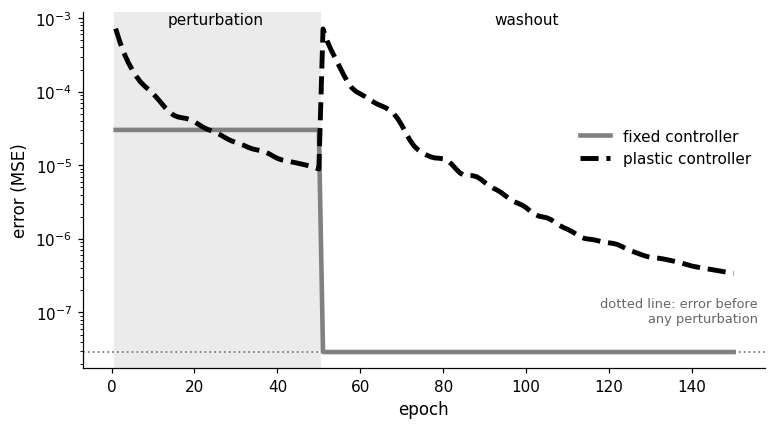

In [21]:
plot_washout(washout, n_perturbation=WASHOUT_PHASES[0][2]); plt.show()

# Part 2 — Controller + adapter (the compound model)

Now we add the **adapter** to the controller and let the two modules learn together. At every time step:

1. the controller produces a command from the task input and the feedback it received;
2. the adapter receives the task input and a copy of the controller's previous command, and produces a correction;
3. the correction is **added** to the controller's command (*readout*) and **fed back** to the controller at the next step (*feedback*, scaled by `gain`);
4. the plant turns the summed command into a hand position.

Here, we first train the compound model on a rotation with two different learning rules. We then use the `model_state` dictionary to switch parts of the adapted network off, to see what the adapter has learned.

## The `model_state` dictionary

The two pathways above, and which weights are allowed to learn, are chosen by the **`model_state`** dictionary.

| key | meaning |
|---|---|
| `cereb_feedback` | adapter output is fed back into the controller (closed loop) |
| `cereb_readout`  | adapter output is added to the controller's motor command |
| `plant` | `True`: the arm maps joint angles to hand position; `False`: identity (outputs are joint angles) |
| `modules_plasticity` | which weights are BP-trainable: `cortex_hw` / `cortex_hb` (controller recurrent weights / biases), `cortex_in`, `cortex_out` (its input / output projections), `cereb_to_cortex` (feedback projection), `cereb` (the whole adapter) |
| `local_plasticity` | controller recurrent weights are updated with a local rule |

It is passed with `model.eval(**model_state)` / `model.train(**model_state)`, which work like the standard `.eval()` and `.train()` of PyTorch models, just extended to accept the model configuration. Because the state is just a dictionary, **ablations are one-line changes**: switch off a pathway and re-run (see the end of this part).

Note: setting both local_plasticity and modules_plasticity['cortex_hw'] to `True` will cause a double update from the BP and the local rule optimization.

## Parameters

These are the knobs to play with: the rotation `ANGLE`, the number of `EPOCHS`, the learning rates, and `FB_GAIN`, the strength of the adapter's feedback to the controller. The adapter learns with a 10 times larger learning rate than the controller, in line with its role as the *transient* component.

The dictionaries below are the `model_state`s used here: `FULL` for evaluating the compound model, `CX_ONLY` for the **controller memory** (adapter switched off), and `STATE_BP` / `STATE_LOCAL` for the two learning rules.

Things to try: set `LR_CX = 0` (the controller cannot learn), raise `LOCAL_LR`, set `FB_GAIN = 0` (no feedback), or `cereb=False` in `STATE_BP` (frozen adapter).

In [22]:
# ══════ 🎛  PARAMETERS: change and re-run ══════
ANGLE    = 40       # rotation applied to the targets (degrees, integer)
EPOCHS   = 200     # one epoch = one full-batch update (all 8 reach directions at once)
LR_CB    = 1e-4     # Adam learning rate, adapter (cerebellum)
LR_CX    = 1e-5     # Adam learning rate, controller (cortex); DL-backprop only
LOCAL_LR = 5e-3     # step size of the local rule; DL-local only
FB_GAIN  = 1        # adapter -> controller feedback gain (inter_specs['gain'] below)

# Full compound model, as used for evaluation.
FULL = dict(cereb_feedback=True, cereb_readout=True, local_plasticity=False,
            plant=True, modules_plasticity=None)

# Controller memory: the adapter is switched off ("what would the controller alone do?")
CX_ONLY = {**FULL, "cereb_feedback": False, "cereb_readout": False}

# Training states (same keys; modules_plasticity says what learns).
STATE_BP = {**FULL, "modules_plasticity": dict(
    cortex_hw=True, cortex_hb=True, cortex_in=False, cortex_out=False,
    cereb_to_cortex=False, cereb=True)}          # which weights learn by backprop
STATE_LOCAL = {**STATE_BP, "local_plasticity": True,
               "modules_plasticity": {**STATE_BP["modules_plasticity"],
                                      "cortex_hw": False, "cortex_hb": False}}
# ═══════════════════════════════════════════════

## Task and architecture

The task and the architecture must match the ones used for pretraining, so treat them as fixed. The one parameter worth knowing about is `gain` in `inter_specs`, which sets the strength of the adapter's feedback to the controller: it is set by `FB_GAIN` above.

In [11]:
dataset_params = dict(
    tasks=8, target="moving", interpolation="bell", timesteps=130,
    hold_cue_time=30, t_in_duration=30, small_ring=False, small_ring_rot=True,
    rings_size=[0.1, 0.05], joints_length=[0.22, 0.27],
    input_type="autoenc", input_mode="full-go",
)
arch = dict(
    hidden_layer_specs=dict(nonlinearity="tanh", init_method="uniform", dt=10, tau=100,
                            in_bias=True, h_bias=True, sigma_rec=0),
    rnn_specs=dict(out_bias=False, sigma_in=0.0, init_method="uniform",
                   nonlin="linear", private_gradients=True),
    cereb_specs=dict(sizes=[1024, 1024], bias=True, init_method="xavier_normal",
                     init_gain=0.1, h_nlin="relu", out_nlin="linear", private_gradients=True),
    inter_specs=dict(weight_distro=["uniform"], bias_distro=["uniform"],
                     autoencoder=False, gain=FB_GAIN),    # gain = strength of the adapter's feedback
    nonlinearity_specs=dict(module="TwoJointsArm"),
)
HIDDEN = 256

def make_task(angle):
    "Reach task rotated by `angle` degrees. Returns inputs x and target hand trajectories y."
    r = ReachingDataset(dataset_params)
    r.apply_perturbation(dict(angle=angle, amplitude_factor=1.0, translation=[0.0, 0.0]))
    return r.generate_perturbed_dataset("cart"), r.input_size[2]

def load_pretrained():
    "Fresh compound model with the pretrained controller and adapter loaded."
    n_in = ReachingDataset(dataset_params).input_size[2]
    model = CerebelloCorticalNet(n_in, HIDDEN, **arch, device="cpu")
    model.cortex.load_state_dict(load_var(PRE / "cortex" / "model.sd"))
    model.cerebellum.load_state_dict(torch.load(PRE / "cerebellum" / "model.sd", map_location="cpu"))
    return model

def run(model, x, state):
    "Forward pass in a given model_state. Returns hand trajectories (time, 8, 2)."
    model.eval(**state)
    with torch.no_grad():
        return model(x)

(x, y), _ = make_task(ANGLE)
model0 = load_pretrained()
colors = plt.get_cmap("rainbow")(np.linspace(0, 1, y.shape[1]))      # one colour per reach direction

## The training loop

The loop below is **not** the normal way to train the model, but something quite close to it. It re-implements, in a few lines, what `CCNetTrainer.train()` does at every epoch, so that the basic mechanisms of the method are visible (see "Normal usage" after this section for the real call). Each epoch is one forward pass over all 8 reach directions, followed by up to three updates:

1. **Adapter** (Adam, `LR_CB`): gradient of the *full-model* error.
2. **Controller** (Adam, `LR_CX`), *DL-backprop only*: gradient of the error with the adapter **switched off** (`CX_ONLY`). The controller learns what the adapter has not already corrected.
3. **Local rule**, *DL-local only*: `model.delta_rule_on_cortex_` updates the controller's recurrent weights from the hidden activity and the adapter output stored during this epoch's full forward pass. No gradient is involved.

The order inside an epoch is the one used by the trainer (its optimizers are sorted `cb` → `cx`, then the local rule, then the logging):

1. Full-model forward pass, then the adapter step on its loss.
2. Controller step, on the loss of a second forward pass with the adapter switched off. The adapter is not part of that pass, so the two steps do not interfere. `opt_cx.zero_grad()` is still needed, because the full-model backward pass leaves gradients on the controller.
3. Local rule (DL-local only). It reads the activity stored by this epoch's full-model forward pass, and any later forward pass overwrites it.

We also log `nocb`, the error of the **controller memory** (adapter switched off): the gap between `mse` and `nocb` is what the adapter contributes, through direct readout and feedback. A live line shows the epoch, the two errors (`mse`, `memory`) and the elapsed time.

In [12]:
def adapt(model_state, phases, label="", lr_cb=LR_CB, lr_cx=LR_CX, local_lr=LOCAL_LR):
    """Simplified re-implementation of the per-epoch logic of CCNetTrainer.train().
    One phase = one trainer.train() call: the weights carry over between phases,
    the optimizers (and their Adam moments) do not."""
    torch.manual_seed(SEED)
    t_start = time.time()
    model = load_pretrained()
    model.train(**model_state)          # sets requires_grad according to modules_plasticity

    cb_params = [p for p in model.cerebellum.parameters() if p.requires_grad]
    cx_params = [p for p in model.cortex.parameters()     if p.requires_grad]

    def forward_cx_only(x):             # same network, adapter switched off
        model.train(**CX_ONLY)
        out, _, _ = model(x, return_hidden=True, return_thetas=True)
        model.train(**model_state)      # switch back
        return out

    # hist has exactly n_epochs entries per phase. trainer.train() returns one extra entry
    # per call (the loss before the first update), which is deliberately left out here.
    hist = dict(phase=[], mse=[], nocb=[])
    for p, (angle, n_epochs) in enumerate(phases):
        (x, y), _ = make_task(angle)
        # Fresh Adam at every phase, as every trainer.train() call rebuilds its optimizers
        # (so the moment estimates do not carry over from one rotation to the next).
        opt_cb = torch.optim.Adam(cb_params, lr=lr_cb) if cb_params else None
        opt_cx = torch.optim.Adam(cx_params, lr=lr_cx) if cx_params else None   # None for DL-local
        for epoch in range(1, n_epochs + 1):
            out, _, _ = model(x, return_hidden=True, return_thetas=True)   # full model
            loss = mse(out, y)

            if opt_cb is not None:                                         # 1. adapter
                opt_cb.zero_grad(); loss.backward(); opt_cb.step()

            if opt_cx is not None:                                         # 2. controller (backprop)
                opt_cx.zero_grad(); mse(forward_cx_only(x), y).backward(); opt_cx.step()

            if model_state["local_plasticity"]:                            # 3. controller (local rule)
                model.delta_rule_on_cortex_(local_lr, "mean")

            with torch.no_grad():                                          # logging
                hist["phase"].append(p)
                hist["mse"].append(loss.item())
                hist["nocb"].append(mse(forward_cx_only(x), y).item())
            if epoch % 10 == 0 or epoch == n_epochs:                       # live progress line
                s = int(time.time() - t_start)
                where = f"phase {p + 1}/{len(phases)} ({angle:+d}°)  " if len(phases) > 1 else ""
                print(f"\r{label}  {where}epoch {epoch:4d}/{n_epochs}  |  "
                      f"mse {hist['mse'][-1]:.2e}  controller memory {hist['nocb'][-1]:.2e}  |  "
                      f"elapsed {s // 60:02d}:{s % 60:02d}", end="", flush=True)
        print()
    return model, {k: np.array(v) for k, v in hist.items()}

## Run both learning rules

Here, the compound model adapts to the rotation with two **distributed learning** rules. They differ in how the controller learns, while the adapter always learns by backprop on the error of the full model.

| | controller (recurrent weights) | adapter |
|---|---|---|
| **DL-backprop** | backprop, on its *own* error (adapter off) | backprop, on the *full-model* error |
| **DL-local** | local delta rule, driven by the adapter's signal | backprop, on the *full-model* error |

In [24]:
model_bp,    hist_bp    = adapt(STATE_BP,    [(ANGLE, EPOCHS)], label="DL-backprop")
model_local, hist_local = adapt(STATE_LOCAL, [(ANGLE, EPOCHS)], label="DL-local   ")

DL-backprop  epoch  200/200  |  mse 3.90e-06  controller memory 1.76e-05  |  elapsed 00:58
DL-local     epoch  200/200  |  mse 4.73e-06  controller memory 1.55e-04  |  elapsed 00:52


### Loss

How well does each rule adapt? The solid line is the error of the full model, and the dashed line the error of the **controller memory**, i.e. the controller with the adapter switched off. The gap between the two is the part of the correction carried by the adapter.

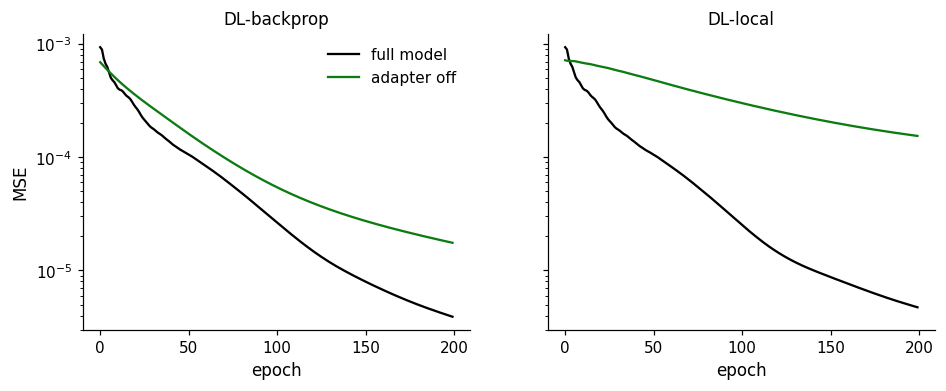

In [25]:
plot_adaptation_loss({"DL-backprop": hist_bp, "DL-local": hist_local}); plt.show()

### Trajectories after adaptation

Here are the hand paths before adaptation, and after adaptation for the full model and for the controller memory (adapter off). Solid lines are the hand paths and dashed lines the rotated targets, both in the colour of their reach.

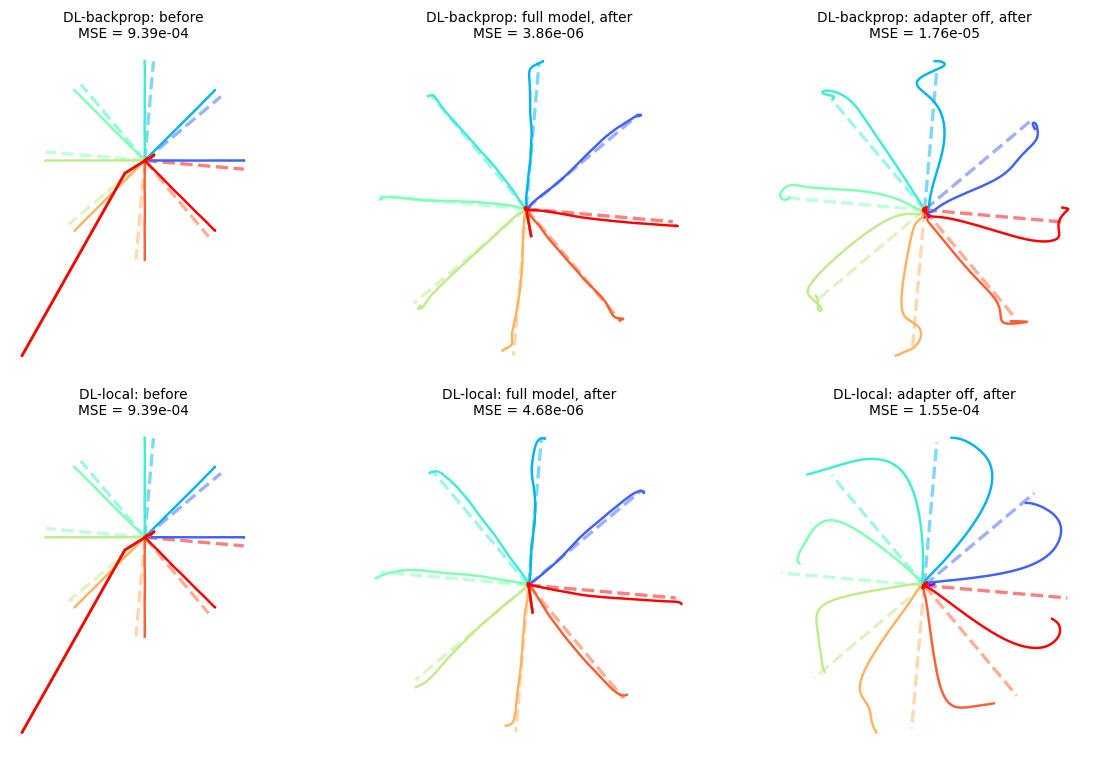

In [26]:
out0 = run(model0, x, FULL)
plot_adaptation_reaches(out0, {
    name: (run(m, x, FULL), run(m, x, CX_ONLY))
    for name, m in [("DL-backprop", model_bp), ("DL-local", model_local)]
}, y, colors); plt.show()

#### Normal usage

In practice, nothing above is written by hand: `train_model.py` builds a `CCNetTrainer` from a JSON config and calls `trainer.train()`. The loop above corresponds to the call below (not run here).


```python
reaching = ReachingDataset(params["dataset_params"])
trainer  = setup_trainer(reaching, params)                   # builds a CCNetTrainer (script_utils)
trainer.load_cortex(load_var(cx_file))                       # pretrained controller
trainer.load_cereb(torch.load(cb_file, map_location=device)) # pretrained adapter
reaching.apply_perturbation(params["perturbation_params"])   # dict(angle=40, amplitude_factor=1.0, translation=[0, 0])
outputs, performance = trainer.train(
    reaching,
    train_params=params["train_params"],
    model_state=params["model_state"],                       # = STATE_BP / STATE_LOCAL
    force=True, **train_settings)                            # train_settings from prepare_training_settings
# Several phases (as in Part 3): repeat apply_perturbation + trainer.train() on the same trainer.
# The weights carry over; the optimizers are rebuilt at every call.
```

How the parameters of this demo map onto `train_params` (JSON config):

| Demo | `train_params` key |
|---|---|
| `EPOCHS` | `epochs` |
| `LR_CB`, `LR_CX` | `cb_lr`, `cx_lr` |
| controller trained on the error with the adapter off | `cx_error: "cx-only"` (default) |
| `LOCAL_LR`, `"mean"` | `local_lr`, `local_method` |
| local rule applied at every epoch | `local_rule_settings: [1, 0, false] (default)` = (step, start, `fb_switch`) |
| (not used in the demo) | `es_params: [300, 1e-9]`, required by the trainer even with early stopping off |

`local_rule_settings`. With `fb_switch: true`, it otpimization switches the adapter feedback off on the epochs without a local update (not used in neither paper nor demo results).

## Ablations with `model_state`

What has the adapter learned, and which pathway carries its correction? Because `model_state` is just a dictionary, we can find out by switching parts of the **adapted** networks off, without any retraining: no feedback to the controller, no readout to the motor command, or the adapter altogether, which leaves the controller memory alone.

Solid lines are the hand paths and dashed lines the targets, both in the colour of their reach. Comparing the panels shows how each pathway contributes to the final reach.

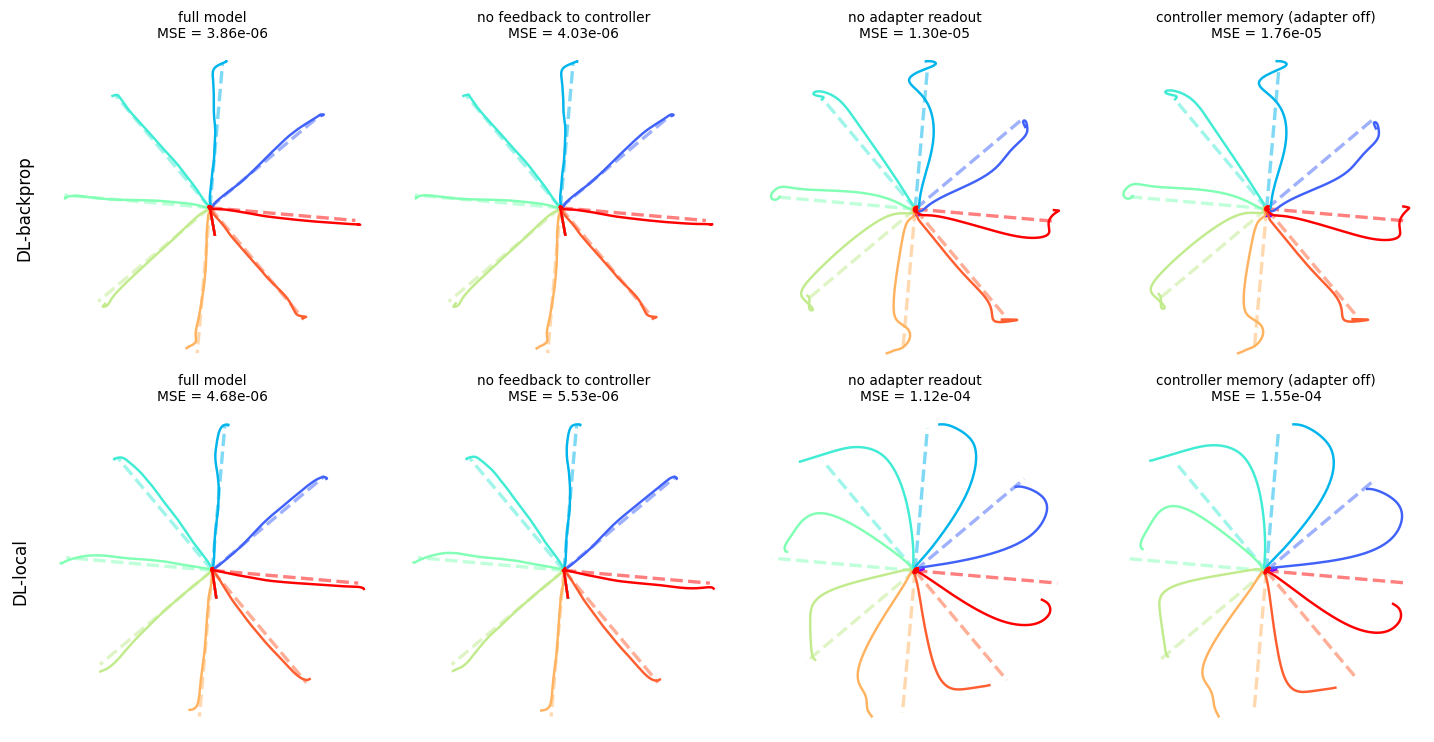

In [27]:
ablations = {
    "full model":                         FULL,
    "no feedback to controller":          {**FULL, "cereb_feedback": False},
    "no adapter readout":                 {**FULL, "cereb_readout": False},
    "controller memory (adapter off)":      CX_ONLY,
}
plot_ablations({
    name: {abl: run(m, x, state) for abl, state in ablations.items()}
    for name, m in [("DL-backprop", model_bp), ("DL-local", model_local)]
}, y, colors); plt.show()

Other switches work the same way. `model.gain = 0` removes the feedback strength without touching the state, and `plant=False` returns joint angles instead of hand positions. In `modules_plasticity`, setting e.g. `cereb=False` freezes the adapter during training: try it in `STATE_BP` and re-run the training above.

---


Here, we repeat the same analysis, but using a higher feedback gain. This change increase the drive the cerebellar/adapter feedback has on the cortex/controller dynamics, and its ability to correct behavior through this pathway. 

Ablating cerebellar readout only partially affect the model output (third column, cf. to previous plot). 

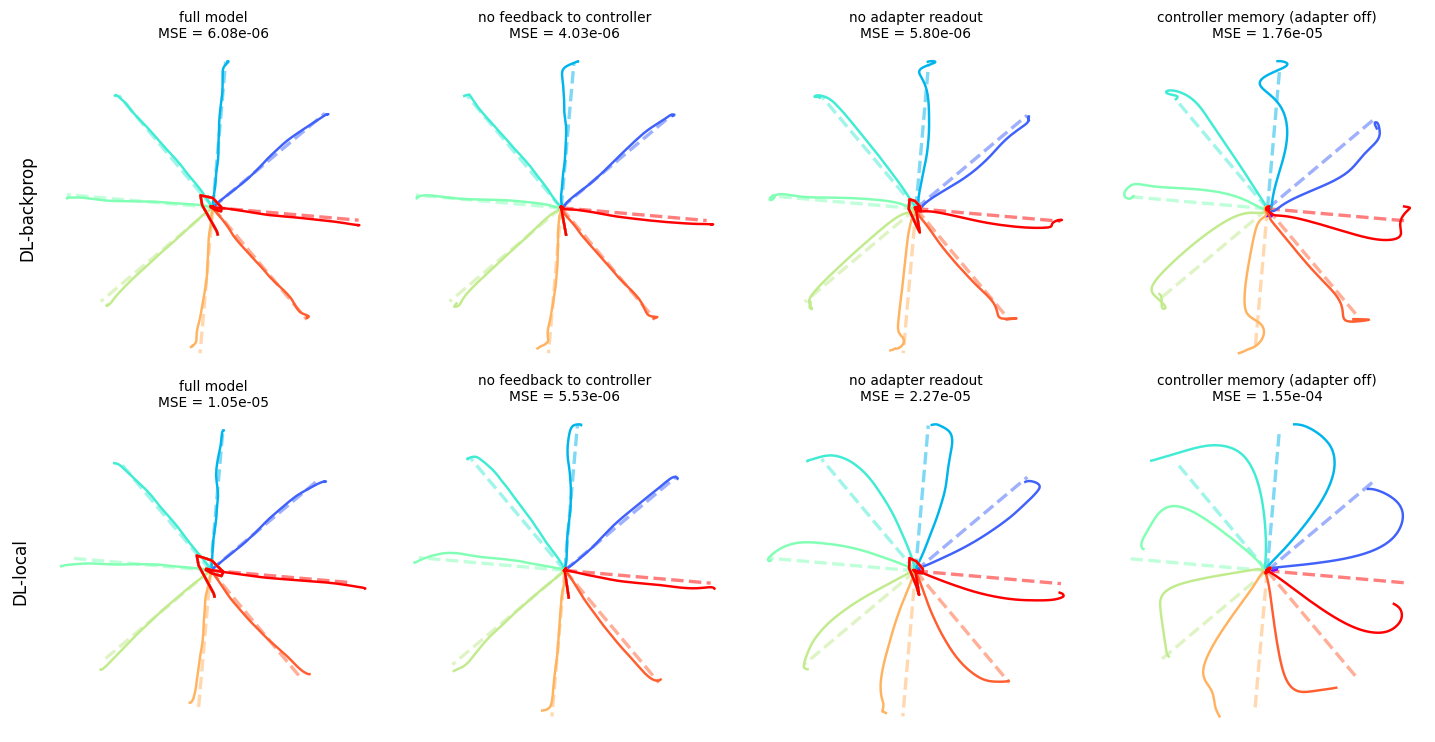

In [28]:
# ══════ 🎛  PARAMETERS: change and re-run ══════
ABLATION_GAIN = 10       # adapter -> controller feedback gain for this plot
# ═══════════════════════════════════════════════

model_bp.gain = ABLATION_GAIN
model_local.gain = ABLATION_GAIN

plot_ablations({
    name: {abl: run(m, x, state) for abl, state in ablations.items()}
    for name, m in [("DL-backprop", model_bp), ("DL-local", model_local)]
}, y, colors); plt.show()

# Part 3 — Savings

Finally, we ask whether the model remembers. The compound model (DL-backprop, `SAVINGS_STATE`) adapts to +40°, is briefly pushed to −40°, and then returns to +40° (schedule in `PHASES`).

**Savings** means that the second +40° adaptation is faster than the first, even though the −40° phase in between has undone much of it. Each phase is a separate training call: the weights carry over, but Adam's moment estimates are reset at every switch, so the speed-up cannot come from optimizer momentum. The plot below overlays the three phases on a common epoch axis, so the speed-up can be read directly.

In [18]:
# ══════ 🎛  PARAMETERS: change and re-run ══════
PHASES        = [(40, 300), (-40, 50), (40, 300)]   # (rotation angle in integer degrees, epochs)
SAVINGS_STATE = STATE_BP                            # or STATE_LOCAL
# ═══════════════════════════════════════════════

model_sv, hist_sv = adapt(SAVINGS_STATE, PHASES, label="Savings")

Savings  phase 1/3 (+40°)  epoch  300/300  |  mse 1.51e-06  controller memory 8.81e-06  |  elapsed 01:38
Savings  phase 2/3 (-40°)  epoch   50/50  |  mse 1.03e-04  controller memory 9.95e-04  |  elapsed 01:52
Savings  phase 3/3 (+40°)  epoch  300/300  |  mse 9.15e-07  controller memory 3.61e-06  |  elapsed 03:23


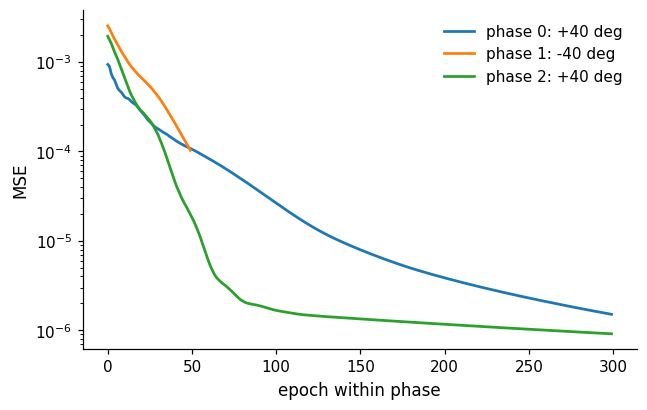

In [19]:
plot_savings(hist_sv, PHASES); plt.show()